# Task 5: Decision Trees and Random Forests Classification
## Clinical Heart Disease Risk Prediction & Model Generalization Analysis

### 1. Project Overview & Objectives
This project demonstrates an end-to-end Machine Learning pipeline comparing **Decision Trees** and **Random Forests** for binary classification on the Heart Disease clinical dataset. The primary objective is to implement, evaluate, interpret, and optimize tree-based models while addressing real-world machine learning challenges:
- **Decision Trees**: Non-parametric supervised learning models that partition feature space using recursive binary splits.
- **Random Forests**: Ensemble learning models that construct a "forest" of diverse decision trees using bootstrap aggregating (bagging) and random feature subspace selection.
- **Overfitting & Regularization**: Controlling tree complexity (depth, minimum sample splits) to prevent training memorization.
- **Impurity Criteria**: Comparing **Gini Impurity** and **Information Gain (Entropy)**.
- **Feature Importance**: Quantifying the clinical predictors driving ensemble decisions.
- **Rigorous Cross-Validation**: Evaluating variance and stability across Stratified 5-Fold partitions.

---

### 2. Technologies Used
- **Python 3.12**: Core programming environment.
- **Pandas & NumPy**: Data wrangling, tabular manipulation, and numerical operations.
- **Matplotlib & Seaborn**: Statistical visualizations and publication-grade figures.
- **Scikit-Learn**: Decision tree and ensemble classifiers, hyperparameter tuning (`GridSearchCV`), model evaluation, and cross-validation.
- **Joblib**: Model serialization and deployment artifact persistence.

---

### 3. Workflow Architecture
1. **Data Exploration & Duplicate Audit**: Schema verification, duplicate identification, and data leakage defense.
2. **Exploratory Data Analysis (EDA)**: Target distribution, continuous feature density, categorical stratification, and correlation analysis.
3. **Data Preprocessing & Stratified Train-Test Split**: Clean separation ensuring test set integrity.
4. **Baseline Decision Tree Modeling**: Initial unconstrained fit and decision logic.
5. **Decision Tree Visualization**: Node-by-node inspection of split thresholds, samples, and purity.
6. **Impurity Mathematics**: Comparative analysis of Gini vs. Entropy.
7. **Overfitting Analysis**: Systematic depth variation vs. generalization error.
8. **Decision Tree Tuning**: Grid search over regularizing hyperparameters.
9. **Random Forest Classifier**: Ensemble construction via bagging and feature subspace sampling.
10. **Random Forest Tuning**: Optimizing ensemble size and tree constraints.
11. **Feature Importance Interpretation**: Impurity-based (MDI) vs. Permutation-based importance.
12. **Cross-Validation**: 5-Fold Stratified CV stability analysis.
13. **Model Evaluation & Diagnostic Curves**: Confusion matrices, Precision-Recall, and ROC curves.
14. **Final Model Comparison & Serialization**: Verification of reloadable `.joblib` artifacts.

> **Clinical Notice**: This project is developed strictly for educational demonstration of tree-based decision models and machine learning workflows. It is not clinically validated or intended for medical diagnosis.

## Section 2: Import Required Libraries and Setup Configuration

We import the necessary libraries for data processing, tree modeling, hyperparameter optimization, and statistical visualization. Visual styling is set to high DPI with consistent color palettes.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Scikit-learn model selection and validation
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    StratifiedKFold,
    GridSearchCV
)

# Tree and Ensemble Classifiers
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_graphviz
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

# Set plotting theme and configurations
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 150
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

# Define relative paths for artifacts
BASE_DIR = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
DATA_PATH = os.path.join(BASE_DIR, 'dataset', 'heart.csv')
VIS_DIR = os.path.join(BASE_DIR, 'outputs', 'visualizations')
MODELS_DIR = os.path.join(BASE_DIR, 'outputs', 'models')
REPORTS_DIR = os.path.join(BASE_DIR, 'outputs', 'reports')

os.makedirs(VIS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(REPORTS_DIR, exist_ok=True)

print("Environment configured successfully.")
print(f"Dataset path: {DATA_PATH}")
print(f"Output directories verified.")

Environment configured successfully.
Dataset path: /Users/pranavagneesh/Desktop/decision-trees-random-forests/dataset/heart.csv
Output directories verified.


## Section 3: Load and Explore Dataset

We load `dataset/heart.csv` using a relative path and inspect its dimensions, data types, missing values, duplicate records, and target distribution.

### Feature Dictionary:
- **`age`**: Age of the patient in years (continuous).
- **`sex`**: Biological sex (1 = male; 0 = female) (binary).
- **`cp`**: Chest pain type (0: typical angina, 1: atypical angina, 2: non-anginal pain, 3: asymptomatic) (nominal).
- **`trestbps`**: Resting blood pressure in mm Hg on admission to the hospital (continuous).
- **`chol`**: Serum cholesterol in mg/dl (continuous).
- **`fbs`**: Fasting blood sugar > 120 mg/dl (1 = true; 0 = false) (binary).
- **`restecg`**: Resting electrocardiographic results (0: normal, 1: ST-T wave abnormality, 2: left ventricular hypertrophy) (nominal).
- **`thalach`**: Maximum heart rate achieved during exercise test (continuous).
- **`exang`**: Exercise-induced angina (1 = yes; 0 = no) (binary).
- **`oldpeak`**: ST depression induced by exercise relative to rest (continuous).
- **`slope`**: Slope of the peak exercise ST segment (0: upsloping, 1: flat, 2: downsloping) (ordinal).
- **`ca`**: Number of major vessels (0-4) colored by fluoroscopy (discrete/ordinal).
- **`thal`**: Thalassemia stress test result (0: null/normal, 1: fixed defect, 2: normal blood flow, 3: reversible defect) (nominal).
- **`target`**: Diagnosis of heart disease (0 = no heart disease, 1 = heart disease present) (binary target).

In [2]:
# Load raw dataset
df_raw = pd.read_csv(DATA_PATH)

print(f"Dataset Shape: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")
print("\nFirst 5 Records:")
display(df_raw.head())

print("\nLast 5 Records:")
display(df_raw.tail())

print("\nDataset Information:")
df_raw.info()

print("\nDescriptive Statistics:")
display(df_raw.describe().round(2))

print("\nMissing Values Count:")
display(df_raw.isnull().sum())

print(f"\nDuplicate Records Count: {df_raw.duplicated().sum()}")
print("\nRaw Target Distribution:")
display(df_raw['target'].value_counts())
print("\nRaw Target Proportion:")
display(df_raw['target'].value_counts(normalize=True).round(4))

Dataset Shape: 1025 rows, 14 columns

First 5 Records:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0



Last 5 Records:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
1020,59,1,1,140,221,0,1,164,1,0.0,2,0,2,1
1021,60,1,0,125,258,0,0,141,1,2.8,1,1,3,0
1022,47,1,0,110,275,0,0,118,1,1.0,1,1,2,0
1023,50,0,0,110,254,0,0,159,0,0.0,2,0,2,1
1024,54,1,0,120,188,0,1,113,0,1.4,1,1,3,0



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB

Descriptive Statistics:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.00,1025.00,1025.00,1025.00,1025.00,1025.00,1025.00,1025.00,1025.00,1025.00,1025.00,1025.00,1025.00,1025.00
mean,54.43,0.70,0.94,131.61,246.00,0.15,0.53,149.11,0.34,1.07,1.39,0.75,2.32,0.51
std,9.07,0.46,1.03,17.52,51.59,0.36,0.53,23.01,0.47,1.18,0.62,1.03,0.62,0.50
min,29.00,0.00,0.00,94.00,126.00,0.00,0.00,71.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,48.00,0.00,0.00,120.00,211.00,0.00,0.00,132.00,0.00,0.00,1.00,0.00,2.00,0.00
50%,56.00,1.00,1.00,130.00,240.00,0.00,1.00,152.00,0.00,0.80,1.00,0.00,2.00,1.00
75%,61.00,1.00,2.00,140.00,275.00,0.00,1.00,166.00,1.00,1.80,2.00,1.00,3.00,1.00
max,77.00,1.00,3.00,200.00,564.00,1.00,2.00,202.00,1.00,6.20,2.00,4.00,3.00,1.00


... (2 outputs left out)


Duplicate Records Count: 723

Raw Target Distribution:


target
1    526
0    499
Name: count, dtype: int64


Raw Target Proportion:


target
1    0.5132
0    0.4868
Name: proportion, dtype: float64

## Section 4: Exploratory Data Analysis (EDA)

Before modeling, we conduct a structured statistical and visual exploration of clinical variables:
1. **Target Distribution**: Assessing class balance.
2. **Numerical Distributions**: Evaluating skewness, kurtosis, and physiological ranges of continuous biomarkers (`age`, `trestbps`, `chol`, `thalach`, `oldpeak`).
3. **Categorical Features**: Stratifying clinical categories against the target outcome.
4. **Correlation Analysis**: Generating a lower-triangular Pearson correlation heatmap.
5. **Feature Relationships**: Examining discriminatory power among key features.

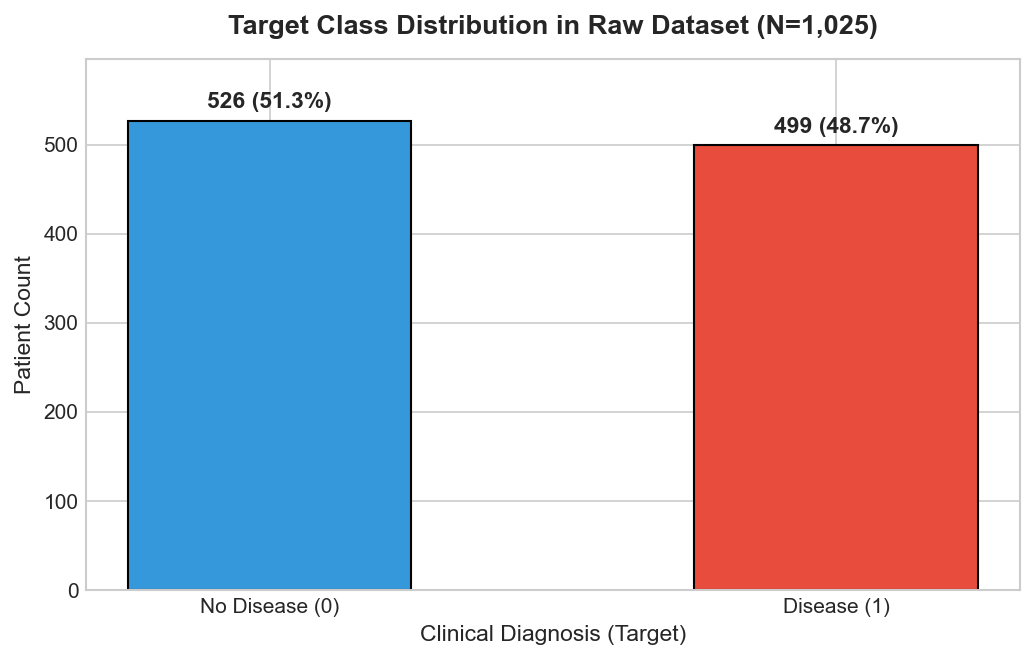

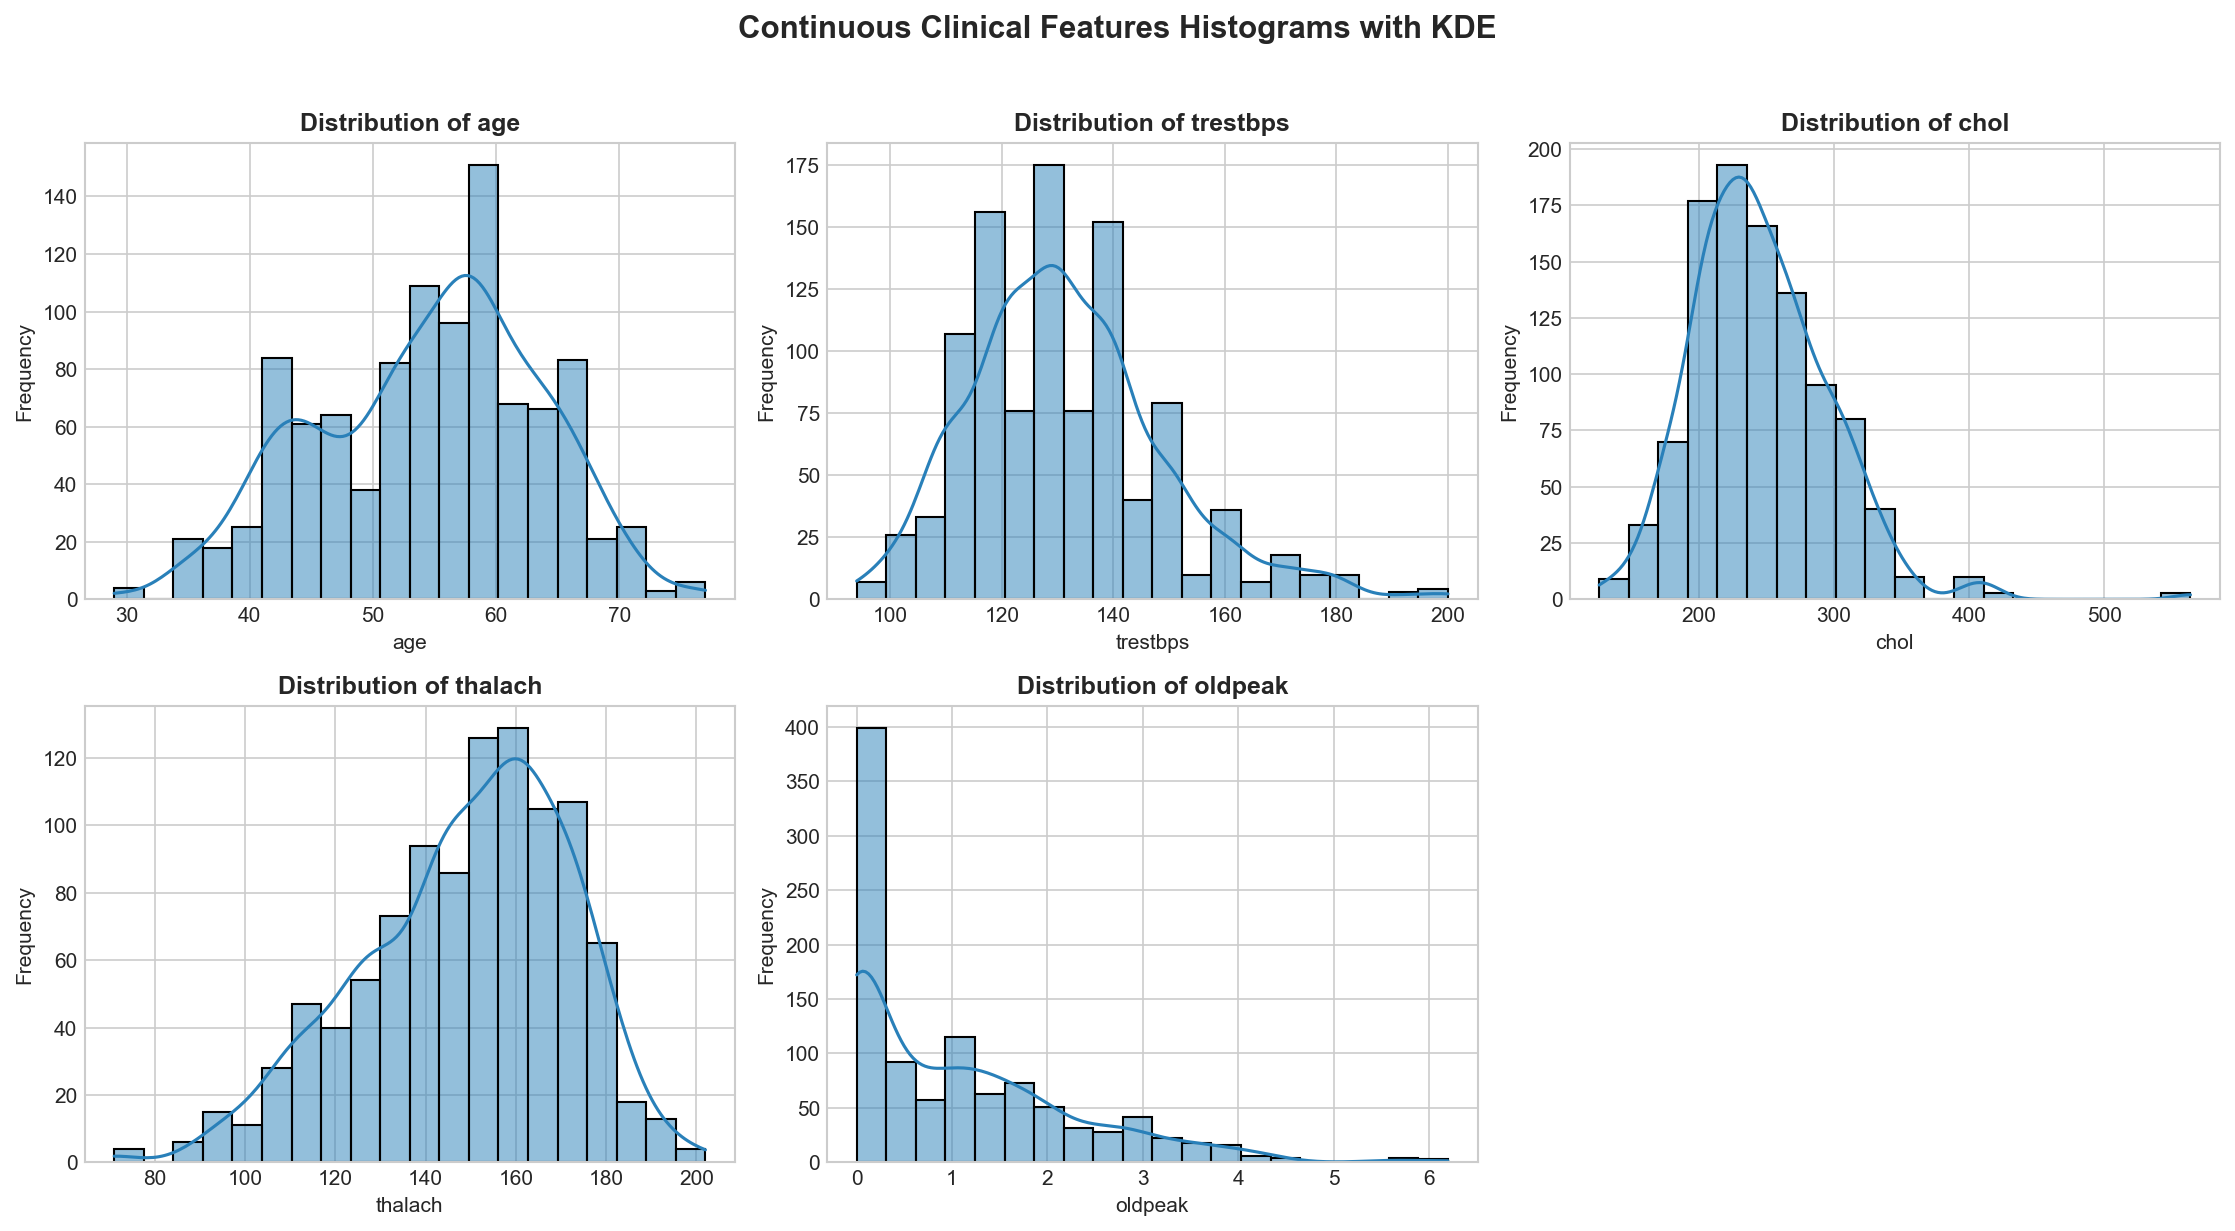

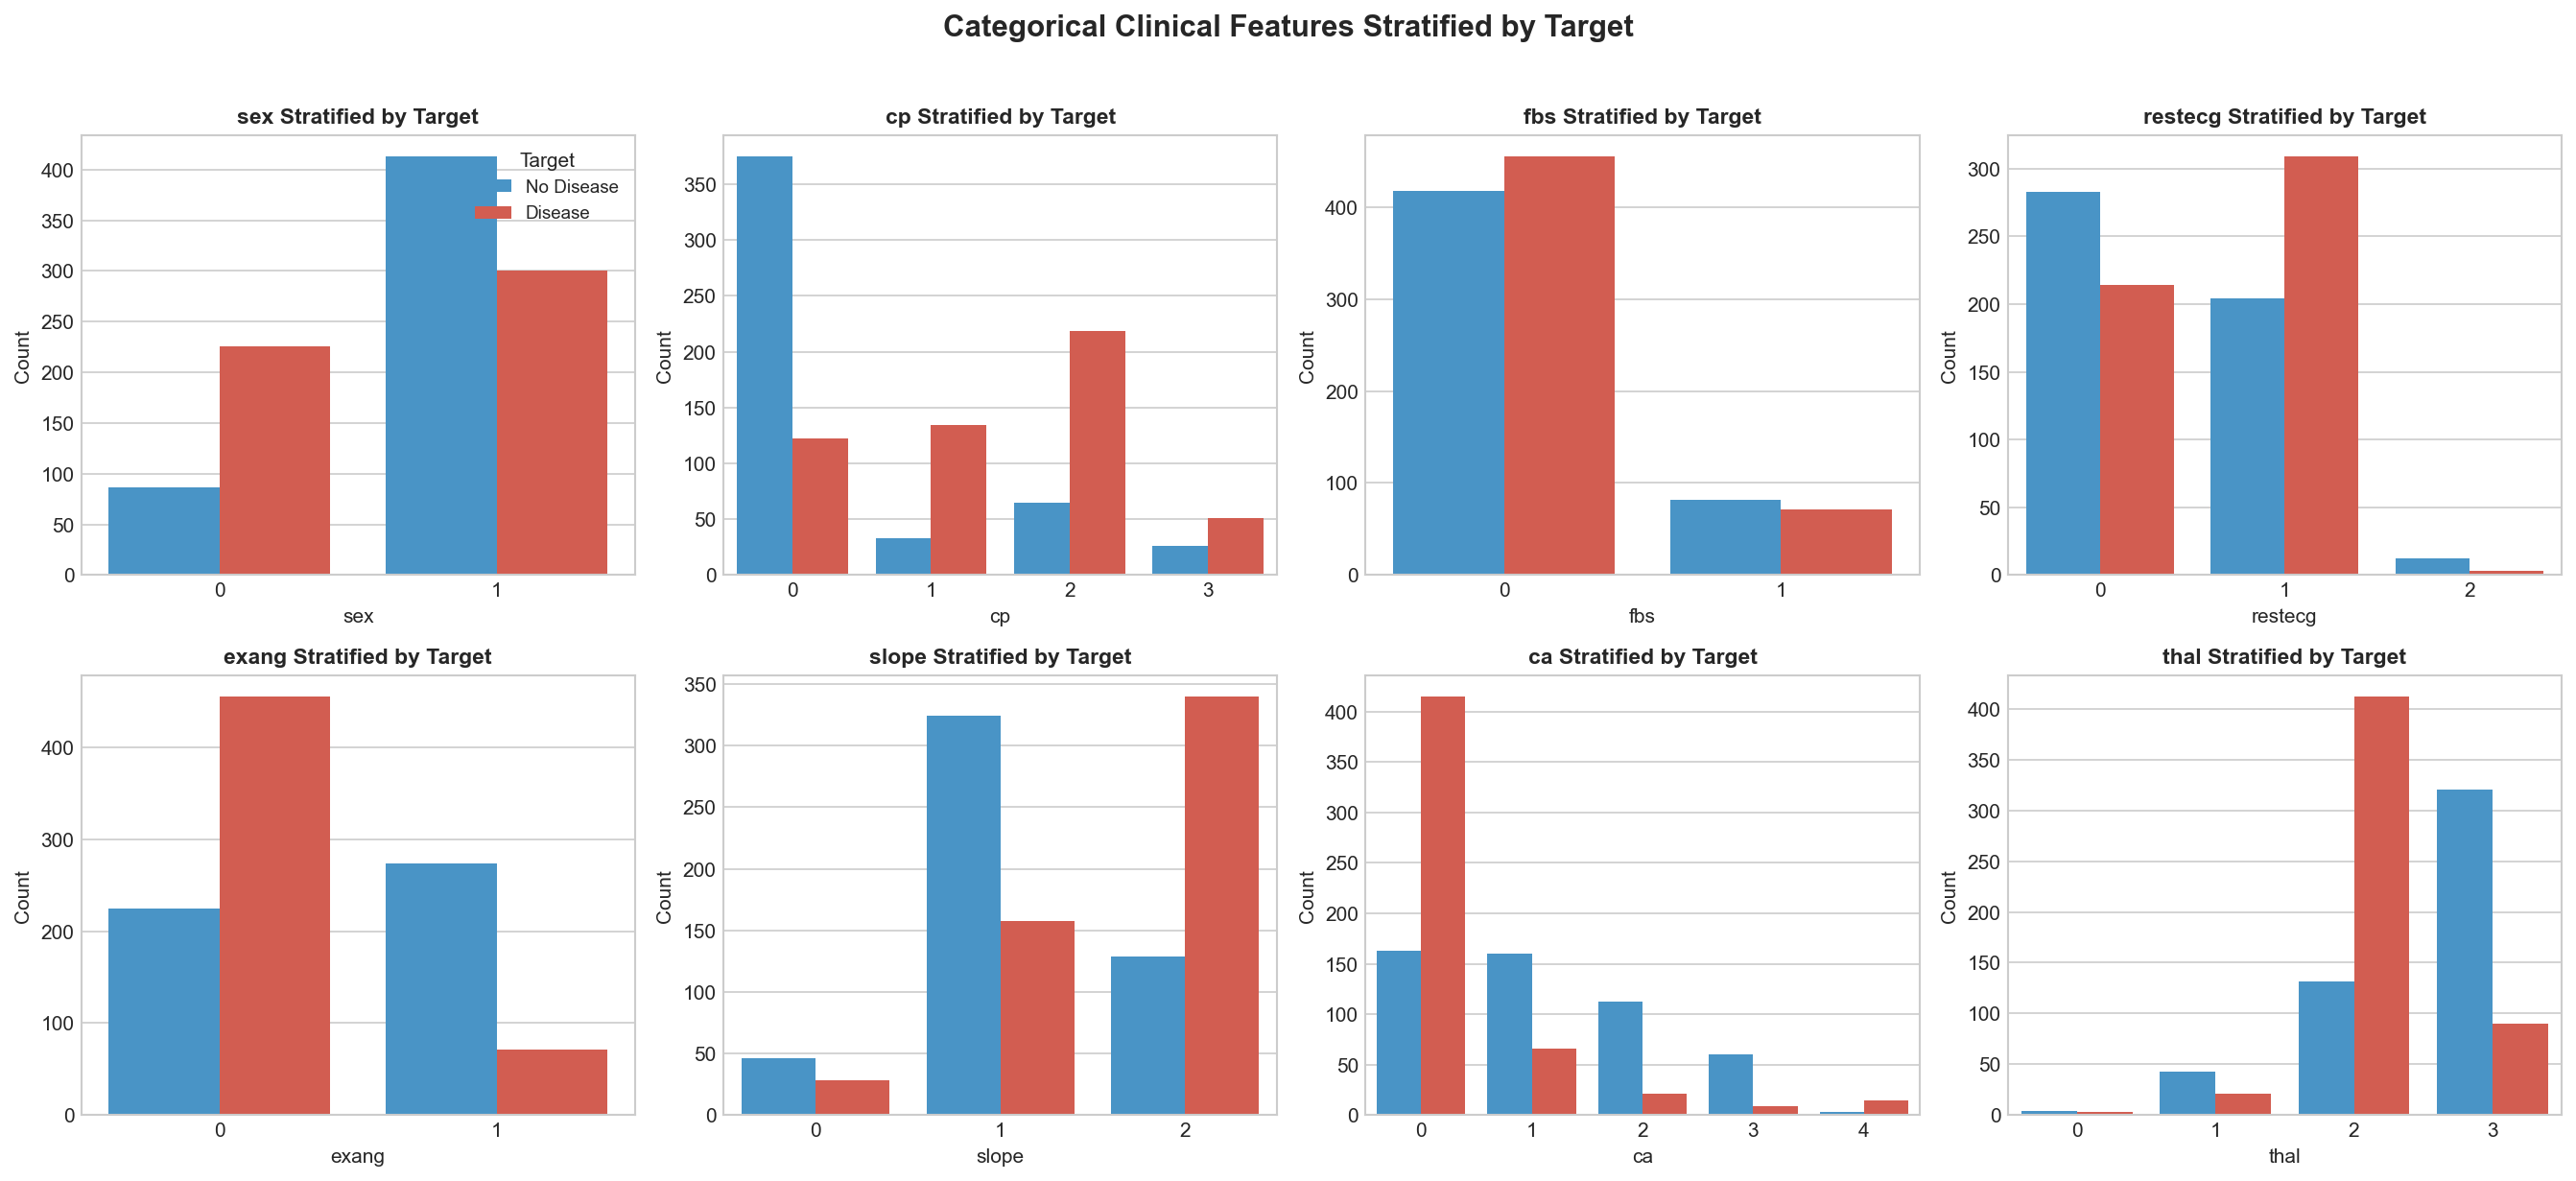

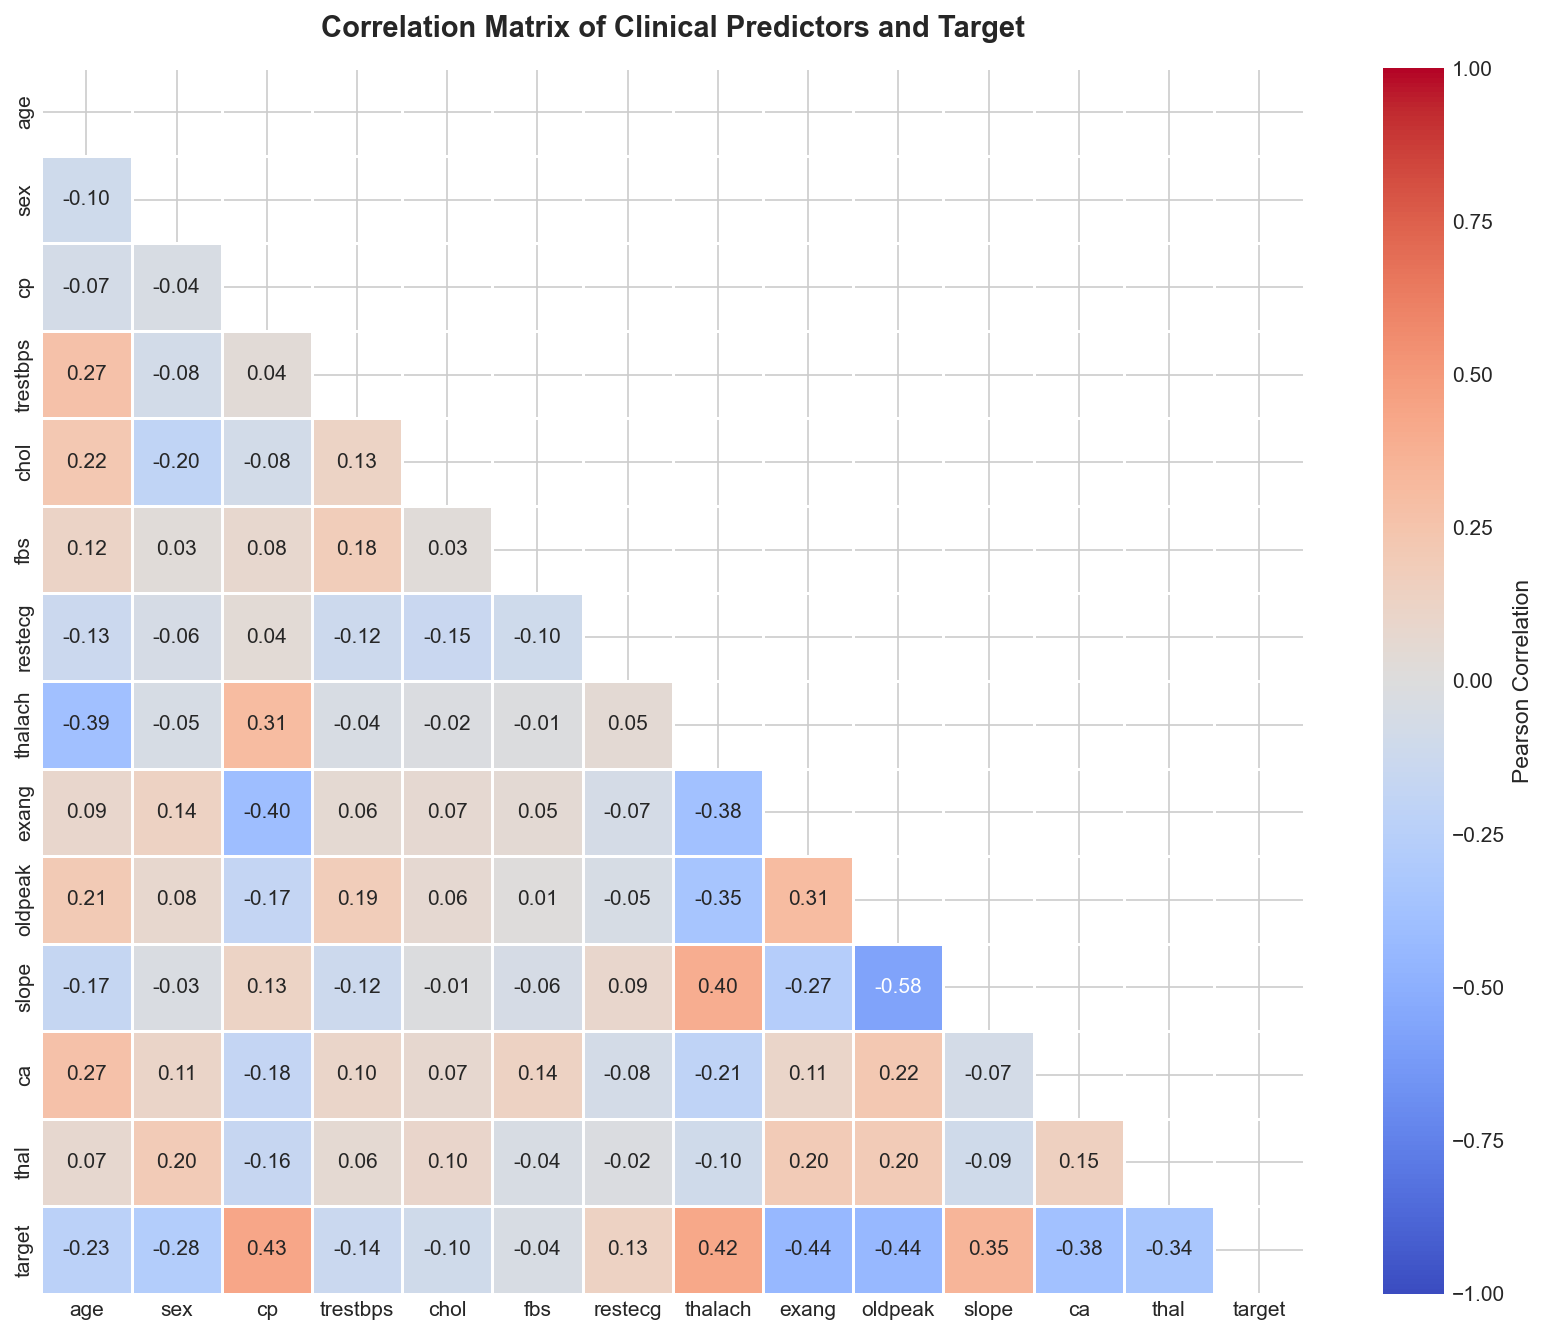

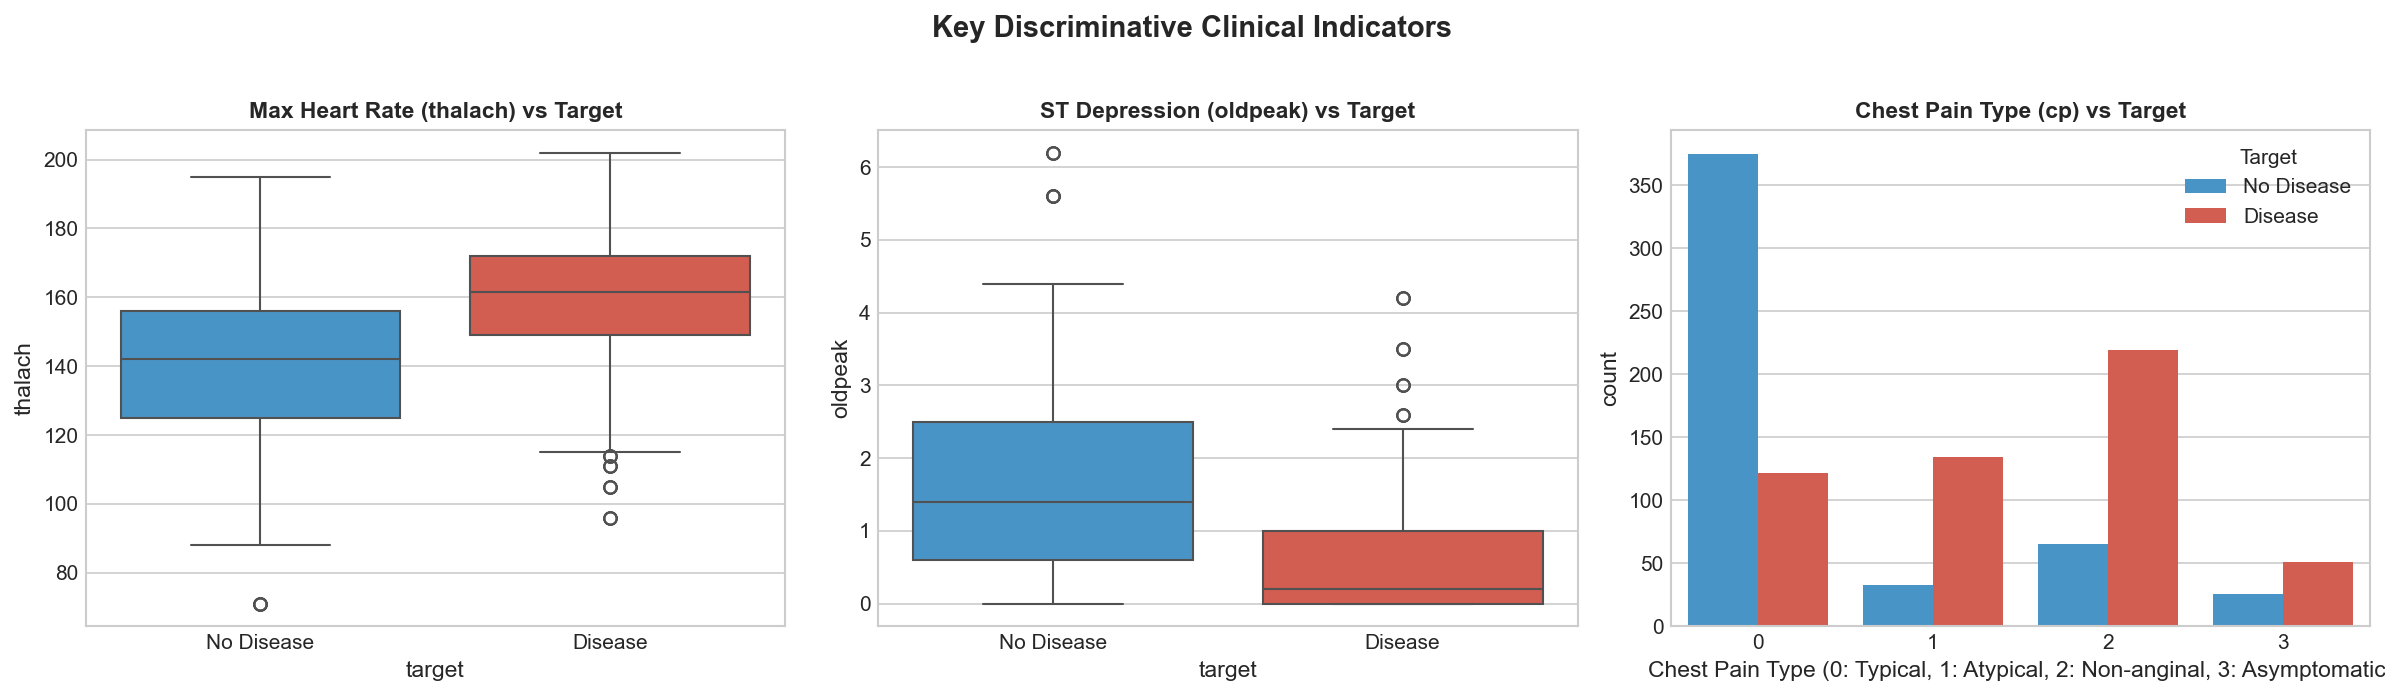

In [3]:
# 4A. Target Distribution Plot
fig, ax = plt.subplots(figsize=(7, 4.5))
counts = df_raw['target'].value_counts()
pcts = df_raw['target'].value_counts(normalize=True) * 100
colors = ['#3498db', '#e74c3c']

bars = ax.bar(['No Disease (0)', 'Disease (1)'], counts, color=colors, edgecolor='black', width=0.5)
for bar, pct, cnt in zip(bars, pcts, counts):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10, f"{cnt} ({pct:.1f}%)", 
            ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_title('Target Class Distribution in Raw Dataset (N=1,025)', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Clinical Diagnosis (Target)', fontsize=11)
ax.set_ylabel('Patient Count', fontsize=11)
ax.set_ylim(0, max(counts) + 70)
plt.tight_layout()
plt.savefig(os.path.join(VIS_DIR, 'target_distribution.png'))
plt.show()

# 4B. Numerical Feature Distributions
num_features = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for idx, col in enumerate(num_features):
    sns.histplot(df_raw[col], kde=True, ax=axes[idx], color='#2980b9', edgecolor='black', bins=20)
    axes[idx].set_title(f'Distribution of {col}', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel(col, fontsize=10)
    axes[idx].set_ylabel('Frequency', fontsize=10)

axes[5].axis('off')
plt.suptitle('Continuous Clinical Features Histograms with KDE', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(VIS_DIR, 'numerical_distributions.png'))
plt.show()

# 4C. Categorical Feature Distributions Stratified by Target
cat_features = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for idx, col in enumerate(cat_features):
    sns.countplot(data=df_raw, x=col, hue='target', ax=axes[idx], palette=['#3498db', '#e74c3c'])
    axes[idx].set_title(f'{col} Stratified by Target', fontsize=11, fontweight='bold')
    axes[idx].set_xlabel(col, fontsize=10)
    axes[idx].set_ylabel('Count', fontsize=10)
    if idx == 0:
        axes[idx].legend(['No Disease', 'Disease'], title='Target', loc='upper right', fontsize=9)
    else:
        axes[idx].legend([], frameon=False)

plt.suptitle('Categorical Clinical Features Stratified by Target', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(VIS_DIR, 'categorical_distributions.png'))
plt.show()

# 4D. Correlation Heatmap
plt.figure(figsize=(11, 9))
corr = df_raw.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, mask=mask, 
            linewidths=0.5, cbar_kws={'label': 'Pearson Correlation'})
plt.title('Correlation Matrix of Clinical Predictors and Target', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig(os.path.join(VIS_DIR, 'correlation_heatmap.png'))
plt.show()

# 4E. Feature Relationships with Target
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.boxplot(x='target', y='thalach', data=df_raw, ax=axes[0], hue='target', palette=['#3498db', '#e74c3c'], legend=False)
axes[0].set_title('Max Heart Rate (thalach) vs Target', fontsize=11, fontweight='bold')
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['No Disease', 'Disease'])

sns.boxplot(x='target', y='oldpeak', data=df_raw, ax=axes[1], hue='target', palette=['#3498db', '#e74c3c'], legend=False)
axes[1].set_title('ST Depression (oldpeak) vs Target', fontsize=11, fontweight='bold')
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['No Disease', 'Disease'])

sns.countplot(x='cp', hue='target', data=df_raw, ax=axes[2], palette=['#3498db', '#e74c3c'])
axes[2].set_title('Chest Pain Type (cp) vs Target', fontsize=11, fontweight='bold')
axes[2].legend(['No Disease', 'Disease'], title='Target')
axes[2].set_xlabel('Chest Pain Type (0: Typical, 1: Atypical, 2: Non-anginal, 3: Asymptomatic)')

plt.suptitle('Key Discriminative Clinical Indicators', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(VIS_DIR, 'feature_target_relationships.png'))
plt.show()

## Section 5: Data Preprocessing and Duplicate Record Investigation

### Critical Dataset Observation:
The dataset contains **723 duplicate rows** out of 1,025 total records (70.54%). 
Before taking any action, we rigorously investigate these duplicates:
1. **Are they exact duplicates?** Yes, across all 14 columns (all 13 clinical features and the target label).
2. **Are there conflicting target labels for identical feature combinations?** No, 0 conflicting rows exist.
3. **Where do these duplicates originate?** The original Cleveland Heart Disease clinical dataset (Detrano et al., 1989) comprises 303 individual patient observations. The 1,025-record dataset was created by resampling/duplicating observations from the original cohort.

### Data Leakage Hazard:
If exact duplicate rows are split randomly across training and testing partitions, the test set receives patient profiles identical to those in the training set. 
- Decision trees and Random Forests will simply "memorize" these duplicate instances.
- This creates an artificial accuracy of ~98-100%, masking severe overfitting.
- Evaluating on deduplicated patient records (302 unique patients) is the only method to assess true out-of-sample generalization.

We retain the original CSV unmodified, document the deduplication process, and use the deduplicated cohort for all downstream modeling.

In [4]:
# Duplicate Audit
n_raw = len(df_raw)
n_dups = df_raw.duplicated().sum()
features_only = [c for c in df_raw.columns if c != 'target']
n_feat_dups = df_raw.duplicated(subset=features_only).sum()

print("--- DUPLICATE AUDIT REPORT ---")
print(f"Original record count: {n_raw}")
print(f"Exact duplicate records: {n_dups} ({n_dups / n_raw * 100:.2f}%)")
print(f"Feature-only duplicates: {n_feat_dups}")
print(f"Conflicting target records: {n_feat_dups - n_dups} (Zero label ambiguity)")

# Create clean deduplicated dataset
df = df_raw.drop_duplicates().reset_index(drop=True)
n_clean = len(df)

print(f"\nClean cohort record count: {n_clean} unique patients")
print("\nTarget Distribution Comparison:")
comp_dist = pd.DataFrame({
    'Raw Count': df_raw['target'].value_counts(),
    'Raw Proportion (%)': (df_raw['target'].value_counts(normalize=True) * 100).round(2),
    'Clean Count': df['target'].value_counts(),
    'Clean Proportion (%)': (df['target'].value_counts(normalize=True) * 100).round(2)
})
display(comp_dist)

--- DUPLICATE AUDIT REPORT ---
Original record count: 1025
Exact duplicate records: 723 (70.54%)
Feature-only duplicates: 723
Conflicting target records: 0 (Zero label ambiguity)

Clean cohort record count: 302 unique patients

Target Distribution Comparison:


,Raw Count,Raw Proportion (%),Clean Count,Clean Proportion (%)
target,,,,
1,526,51.32,164,54.3
0,499,48.68,138,45.7


## Section 6: Train-Test Split

We separate feature matrix `X` from target vector `y` and perform an 80/20 train-test split:
- **`test_size = 0.20`**: Allocates 20% of unique patients (61 samples) to the untouched test set, preserving 80% (241 samples) for training and cross-validation.
- **`random_state = 42`**: Enforces strict experimental reproducibility.
- **`stratify = y`**: Preserves the exact 54.3% vs. 45.7% class ratio across both partitions, preventing distribution shift in small clinical cohorts.

In [5]:
# Separate features and target
X = df.drop(columns=['target'])
y = df['target']
feature_names = list(X.columns)

# Perform Stratified Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Feature Matrix X: {X.shape[0]} rows, {X.shape[1]} features")
print(f"Training set: {X_train.shape[0]} samples ({(len(X_train)/len(df))*100:.1f}%)")
print(f"Testing set: {X_test.shape[0]} samples ({(len(X_test)/len(df))*100:.1f}%)")
print(f"\nTraining Class Distribution:\n{y_train.value_counts(normalize=True).round(4)}")
print(f"\nTesting Class Distribution:\n{y_test.value_counts(normalize=True).round(4)}")

Feature Matrix X: 302 rows, 13 features
Training set: 241 samples (79.8%)
Testing set: 61 samples (20.2%)

Training Class Distribution:
target
1    0.5436
0    0.4564
Name: proportion, dtype: float64

Testing Class Distribution:
target
1    0.541
0    0.459
Name: proportion, dtype: float64


## Section 7: Decision Tree Classifier (Baseline)

A **Decision Tree** is a non-parametric supervised learning algorithm. Starting at the root node, it recursively chooses the feature and split threshold that maximizes impurity reduction (e.g., Gini or Entropy).
Here we train an unconstrained baseline (`max_depth=None`, `random_state=42`).

In [6]:
# Instantiate and train baseline Decision Tree
dt_baseline = DecisionTreeClassifier(random_state=42)
dt_baseline.fit(X_train, y_train)

# Predictions
y_train_pred_dt_base = dt_baseline.predict(X_train)
y_test_pred_dt_base = dt_baseline.predict(X_test)

train_acc_dt_base = accuracy_score(y_train, y_train_pred_dt_base)
test_acc_dt_base = accuracy_score(y_test, y_test_pred_dt_base)

print("--- BASELINE DECISION TREE RESULTS ---")
print(f"Maximum Tree Depth Reached: {dt_baseline.get_depth()}")
print(f"Total Leaf Nodes Formed: {dt_baseline.get_n_leaves()}")
print(f"Training Accuracy: {train_acc_dt_base:.4f} ({train_acc_dt_base * 100:.1f}%)")
print(f"Testing Accuracy:  {test_acc_dt_base:.4f} ({test_acc_dt_base * 100:.1f}%)")
print(f"Generalization Gap: {train_acc_dt_base - test_acc_dt_base:.4f}")

--- BASELINE DECISION TREE RESULTS ---
Maximum Tree Depth Reached: 9
Total Leaf Nodes Formed: 35
Training Accuracy: 1.0000 (100.0%)
Testing Accuracy:  0.8033 (80.3%)
Generalization Gap: 0.1967


## Section 8: Decision Tree Visualization

We visualize the learned tree topology using `sklearn.tree.plot_tree`. To ensure clinical interpretability without visual clutter, we prune the display view to depth 3:
- **Node Anatomy**: Shows the splitting feature threshold, Gini impurity, total sample count, sample distribution per class `[No Disease, Disease]`, and majority class label.
- We also export the structure as a Graphviz `.dot` file.

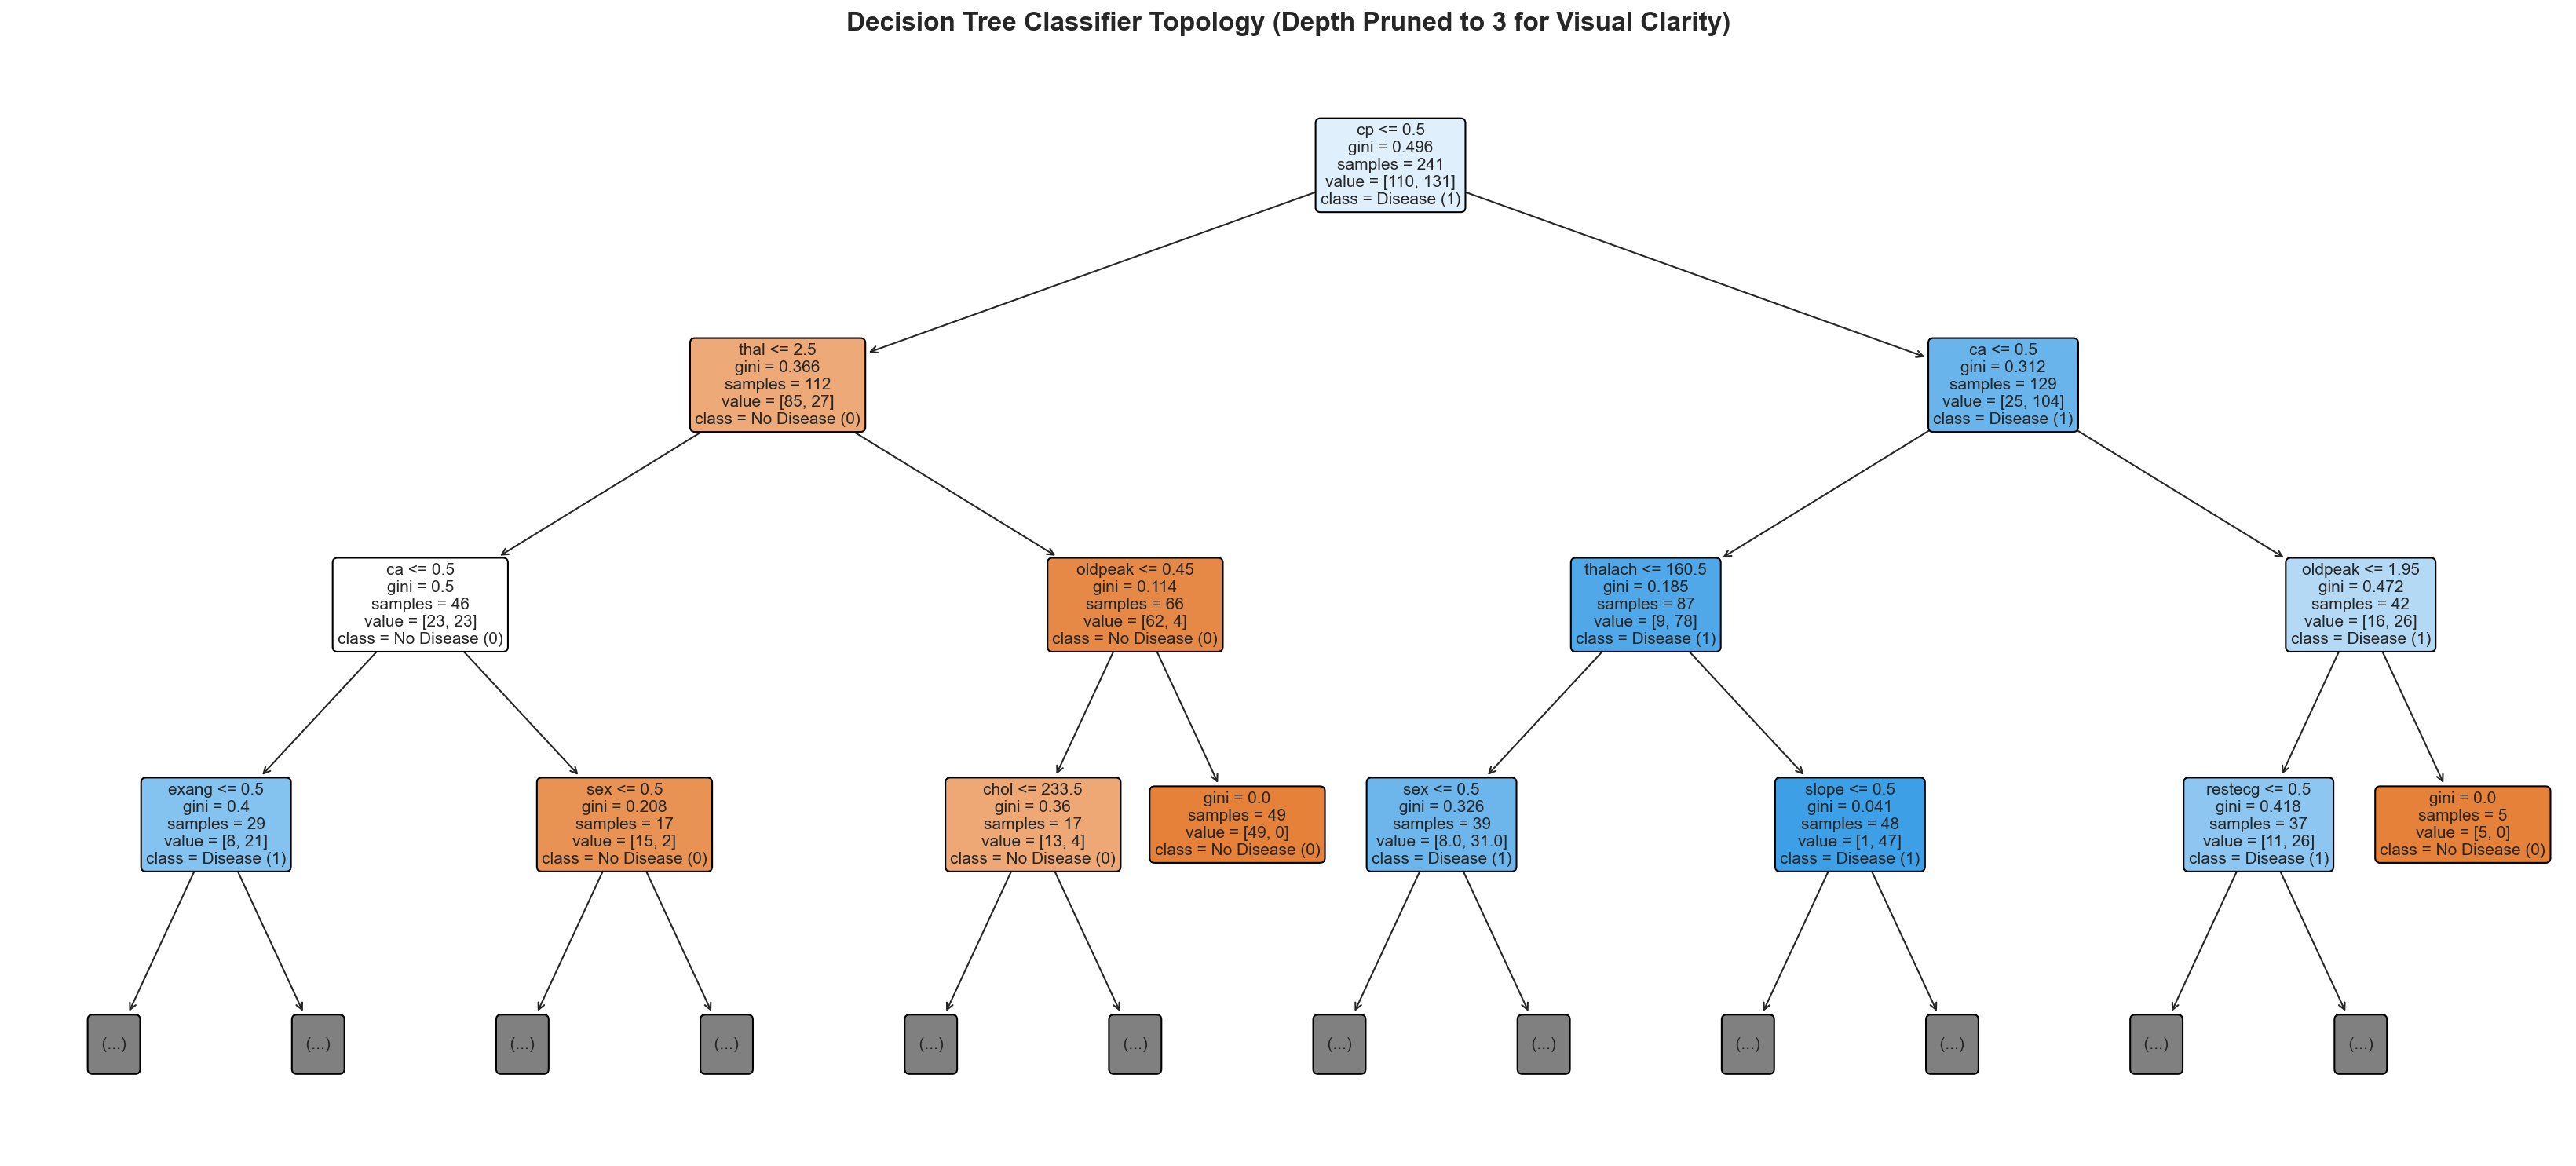

Graphviz DOT file successfully generated at: /Users/pranavagneesh/Desktop/decision-trees-random-forests/outputs/visualizations/decision_tree.dot


In [7]:
# Plot tree with scikit-learn plot_tree
plt.figure(figsize=(22, 10))
plot_tree(
    dt_baseline,
    max_depth=3,
    feature_names=feature_names,
    class_names=['No Disease (0)', 'Disease (1)'],
    filled=True,
    rounded=True,
    fontsize=10,
    impurity=True
)
plt.title('Decision Tree Classifier Topology (Depth Pruned to 3 for Visual Clarity)', fontsize=16, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig(os.path.join(VIS_DIR, 'decision_tree.png'))
plt.show()

# Export DOT format
dot_file_path = os.path.join(VIS_DIR, 'decision_tree.dot')
export_graphviz(
    dt_baseline,
    out_file=dot_file_path,
    max_depth=3,
    feature_names=feature_names,
    class_names=['No Disease', 'Disease'],
    filled=True,
    rounded=True,
    special_characters=True
)
print(f"Graphviz DOT file successfully generated at: {dot_file_path}")

## Section 9: Entropy, Information Gain, and Gini Impurity

### Mathematical Formulations:
For a node $m$ containing proportions $p_k$ for class $k \in \{0, 1\}$:

1. **Gini Impurity**:
   $$I_G(m) = 1 - \sum_{k=0}^{1} p_k^2$$
   - Measures the probability of misclassifying a randomly chosen element if it were randomly labeled according to the class distribution.
   - Ranges from 0 (pure node) to 0.5 (maximum impurity in binary classification).
   - Computationally faster as it avoids logarithmic computations.

2. **Entropy**:
   $$H(m) = -\sum_{k=0}^{1} p_k \log_2(p_k)$$
   - Rooted in Information Theory (Shannon entropy), measuring the disorder or average information content.
   - Ranges from 0 (pure node) to 1.0 (equal binary distribution).

3. **Information Gain**:
   $$IG(T, a) = H(T) - \sum_{v \in \text{vals}(a)} \frac{|T_v|}{|T|} H(T_v)$$
   - The reduction in entropy achieved by partitioning the dataset $T$ on attribute $a$.

We train separate decision trees using both criteria and compare test metrics.

In [8]:
# Compare Gini vs Entropy
dt_gini = DecisionTreeClassifier(criterion='gini', random_state=42).fit(X_train, y_train)
dt_entropy = DecisionTreeClassifier(criterion='entropy', random_state=42).fit(X_train, y_train)

gini_test_acc = accuracy_score(y_test, dt_gini.predict(X_test))
gini_test_auc = roc_auc_score(y_test, dt_gini.predict_proba(X_test)[:, 1])

entropy_test_acc = accuracy_score(y_test, dt_entropy.predict(X_test))
entropy_test_auc = roc_auc_score(y_test, dt_entropy.predict_proba(X_test)[:, 1])

criterion_comparison = pd.DataFrame([
    {'Criterion': 'Gini Impurity', 'Test Accuracy': gini_test_acc, 'Test ROC-AUC': gini_test_auc, 'Tree Depth': dt_gini.get_depth(), 'Leaves': dt_gini.get_n_leaves()},
    {'Criterion': 'Entropy / Info Gain', 'Test Accuracy': entropy_test_acc, 'Test ROC-AUC': entropy_test_auc, 'Tree Depth': dt_entropy.get_depth(), 'Leaves': dt_entropy.get_n_leaves()}
])

display(criterion_comparison.round(4))

,Criterion,Test Accuracy,Test ROC-AUC,Tree Depth,Leaves
0,Gini Impurity,0.8033,0.8019,9,35
1,Entropy / Info Gain,0.7213,0.7208,11,35


## Section 10: Analyze Overfitting and Tree Depth Optimization

An unconstrained Decision Tree continually splits until every training sample is isolated into a pure leaf node ($I_G = 0$). This causes **100% training accuracy** and severe overfitting: the tree memorizes idiosyncratic noise rather than true population patterns.

We systematically vary `max_depth` from 1 to 10 and `None`, evaluating training accuracy, testing accuracy, and the generalization gap.

,max_depth,Train Accuracy,Test Accuracy,Generalization Gap
0,1,0.7842,0.6557,0.1285
1,2,0.7842,0.6557,0.1285
2,3,0.8589,0.8033,0.0556
3,4,0.8714,0.7213,0.1501
4,5,0.9419,0.7705,0.1714
5,6,0.9627,0.7705,0.1922
6,7,0.9793,0.7705,0.2088
7,8,0.9959,0.7869,0.2090
8,9,1.0000,0.8033,0.1967
9,10,1.0000,0.8033,0.1967


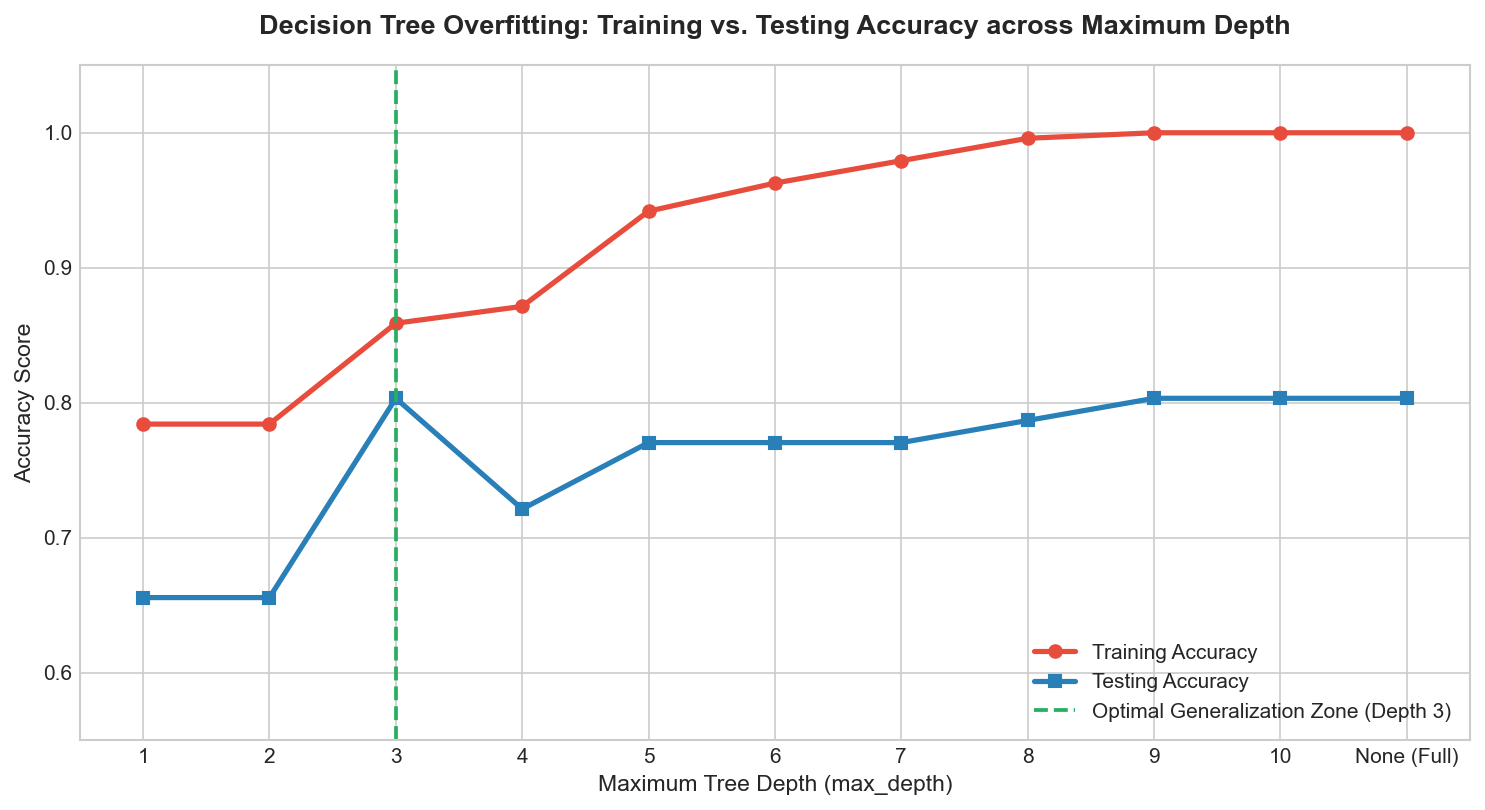

In [9]:
# Evaluate tree depth progression
depths = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, None]
depth_records = []

for d in depths:
    clf = DecisionTreeClassifier(max_depth=d, random_state=42)
    clf.fit(X_train, y_train)
    tr_acc = accuracy_score(y_train, clf.predict(X_train))
    te_acc = accuracy_score(y_test, clf.predict(X_test))
    depth_records.append({
        'max_depth': str(d) if d is not None else 'None (Full)',
        'Train Accuracy': round(tr_acc, 4),
        'Test Accuracy': round(te_acc, 4),
        'Generalization Gap': round(tr_acc - te_acc, 4)
    })

df_depth_analysis = pd.DataFrame(depth_records)
display(df_depth_analysis)

# Plot Overfitting Curve
fig, ax = plt.subplots(figsize=(10, 5.5))
x_labels = [r['max_depth'] for r in depth_records]
train_curve = [r['Train Accuracy'] for r in depth_records]
test_curve = [r['Test Accuracy'] for r in depth_records]

ax.plot(x_labels, train_curve, marker='o', linewidth=2.5, color='#e74c3c', label='Training Accuracy')
ax.plot(x_labels, test_curve, marker='s', linewidth=2.5, color='#2980b9', label='Testing Accuracy')
ax.axvline(x='3', color='#27ae60', linestyle='--', linewidth=1.8, label='Optimal Generalization Zone (Depth 3)')

ax.set_title('Decision Tree Overfitting: Training vs. Testing Accuracy across Maximum Depth', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Maximum Tree Depth (max_depth)', fontsize=11)
ax.set_ylabel('Accuracy Score', fontsize=11)
ax.set_ylim(0.55, 1.05)
ax.legend(loc='lower right', fontsize=10)

plt.tight_layout()
plt.savefig(os.path.join(VIS_DIR, 'decision_tree_depth_analysis.png'))
plt.show()

## Section 11: Decision Tree Hyperparameter Tuning with GridSearchCV

To regularize the Decision Tree systematically, we execute a 5-fold Stratified Cross-Validation Grid Search over key structural constraints:
- `criterion`: `['gini', 'entropy']`
- `max_depth`: `[2, 3, 4, 5, 6, 8, None]`
- `min_samples_split`: `[2, 5, 10, 15]`
- `min_samples_leaf`: `[1, 2, 4, 6]`

Scoring metric: **ROC-AUC** on training cross-validation folds.

In [10]:
# Hyperparameter search for Decision Tree
cv_kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

dt_param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [2, 3, 4, 5, 6, 8, None],
    'min_samples_split': [2, 5, 10, 15],
    'min_samples_leaf': [1, 2, 4, 6]
}

dt_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid=dt_param_grid,
    cv=cv_kfold,
    scoring='roc_auc',
    n_jobs=-1
)

dt_grid.fit(X_train, y_train)
dt_best = dt_grid.best_estimator_

print("--- DECISION TREE GRID SEARCH RESULTS ---")
print(f"Optimal Hyperparameters: {dt_grid.best_params_}")
print(f"Best CV ROC-AUC: {dt_grid.best_score_:.4f}")
print(f"Test Set Accuracy: {accuracy_score(y_test, dt_best.predict(X_test)):.4f}")
print(f"Test Set ROC-AUC:  {roc_auc_score(y_test, dt_best.predict_proba(X_test)[:, 1]):.4f}")

--- DECISION TREE GRID SEARCH RESULTS ---
Optimal Hyperparameters: {'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 4, 'min_samples_split': 10}
Best CV ROC-AUC: 0.8787
Test Set Accuracy: 0.7213
Test Set ROC-AUC:  0.8328


## Section 12: Random Forest Classifier (Baseline)

A **Random Forest** is an ensemble learner that combines multiple decision trees to decrease variance without increasing bias. It introduces two layers of randomness:
1. **Bootstrap Aggregating (Bagging)**: Each tree is trained on a distinct bootstrap sample drawn with replacement from the training data.
2. **Random Subspace Method**: At each candidate split, only a random subset of features (typically $\sqrt{p}$) is evaluated, decorrelating individual trees.
3. **Aggregation**: Individual tree probability predictions are averaged, and final class assignment occurs via majority vote.

We train an initial baseline with `n_estimators=100` and `random_state=42`.

In [11]:
# Train Baseline Random Forest
rf_baseline = RandomForestClassifier(n_estimators=100, random_state=42)
rf_baseline.fit(X_train, y_train)

y_train_pred_rf_base = rf_baseline.predict(X_train)
y_test_pred_rf_base = rf_baseline.predict(X_test)

train_acc_rf_base = accuracy_score(y_train, y_train_pred_rf_base)
test_acc_rf_base = accuracy_score(y_test, y_test_pred_rf_base)

print("--- BASELINE RANDOM FOREST RESULTS ---")
print(f"Number of Estimators: {rf_baseline.n_estimators}")
print(f"Training Accuracy: {train_acc_rf_base:.4f} ({train_acc_rf_base * 100:.1f}%)")
print(f"Testing Accuracy:  {test_acc_rf_base:.4f} ({test_acc_rf_base * 100:.1f}%)")
print(f"Generalization Gap: {train_acc_rf_base - test_acc_rf_base:.4f}")

--- BASELINE RANDOM FOREST RESULTS ---
Number of Estimators: 100
Training Accuracy: 1.0000 (100.0%)
Testing Accuracy:  0.7541 (75.4%)
Generalization Gap: 0.2459


## Section 13: Random Forest Hyperparameter Tuning

We optimize the Random Forest ensemble using `GridSearchCV` across:
- `n_estimators`: `[50, 100, 150]`
- `max_depth`: `[3, 5, 8, None]`
- `min_samples_split`: `[2, 5, 10]`
- `min_samples_leaf`: `[1, 2, 4]`
- `max_features`: `['sqrt', 'log2']`

In [12]:
# Hyperparameter search for Random Forest
rf_param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [3, 5, 8, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2']
}

rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid=rf_param_grid,
    cv=cv_kfold,
    scoring='roc_auc',
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)
rf_best = rf_grid.best_estimator_

print("--- RANDOM FOREST GRID SEARCH RESULTS ---")
print(f"Optimal Hyperparameters: {rf_grid.best_params_}")
print(f"Best CV ROC-AUC: {rf_grid.best_score_:.4f}")
print(f"Test Set Accuracy: {accuracy_score(y_test, rf_best.predict(X_test)):.4f}")
print(f"Test Set ROC-AUC:  {roc_auc_score(y_test, rf_best.predict_proba(X_test)[:, 1]):.4f}")

--- RANDOM FOREST GRID SEARCH RESULTS ---
Optimal Hyperparameters: {'max_depth': 3, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 50}
Best CV ROC-AUC: 0.9197
Test Set Accuracy: 0.7869
Test Set ROC-AUC:  0.8831


## Section 14: Random Forest Feature Importance

Random Forests quantify feature contributions through **Mean Decrease in Impurity (MDI)**, measuring total impurity reduction accumulated across all splits in all ensemble trees.
- **Caution**: MDI can favor features with many split points. To validate, we also compute **Permutation Importance** on the test set.
- **Causation Disclaimer**: High predictive importance indicates correlation with heart disease diagnosis in this sample, not clinical causality.

,Feature,MDI_Importance,Permutation_Mean,Permutation_Std,Rank
0,cp,0.240511,-0.003279,0.019118,1
1,ca,0.164066,0.047541,0.020011,2
2,exang,0.143479,0.019672,0.022951,3
3,thal,0.114417,0.036066,0.009836,4
4,thalach,0.113018,0.008197,0.036103,5
5,oldpeak,0.078043,0.034426,0.027869,6
6,age,0.039802,-0.001639,0.011475,7
7,sex,0.032398,0.024590,0.022297,8
8,chol,0.027686,-0.008197,0.010997,9
9,slope,0.025980,0.034426,0.011475,10


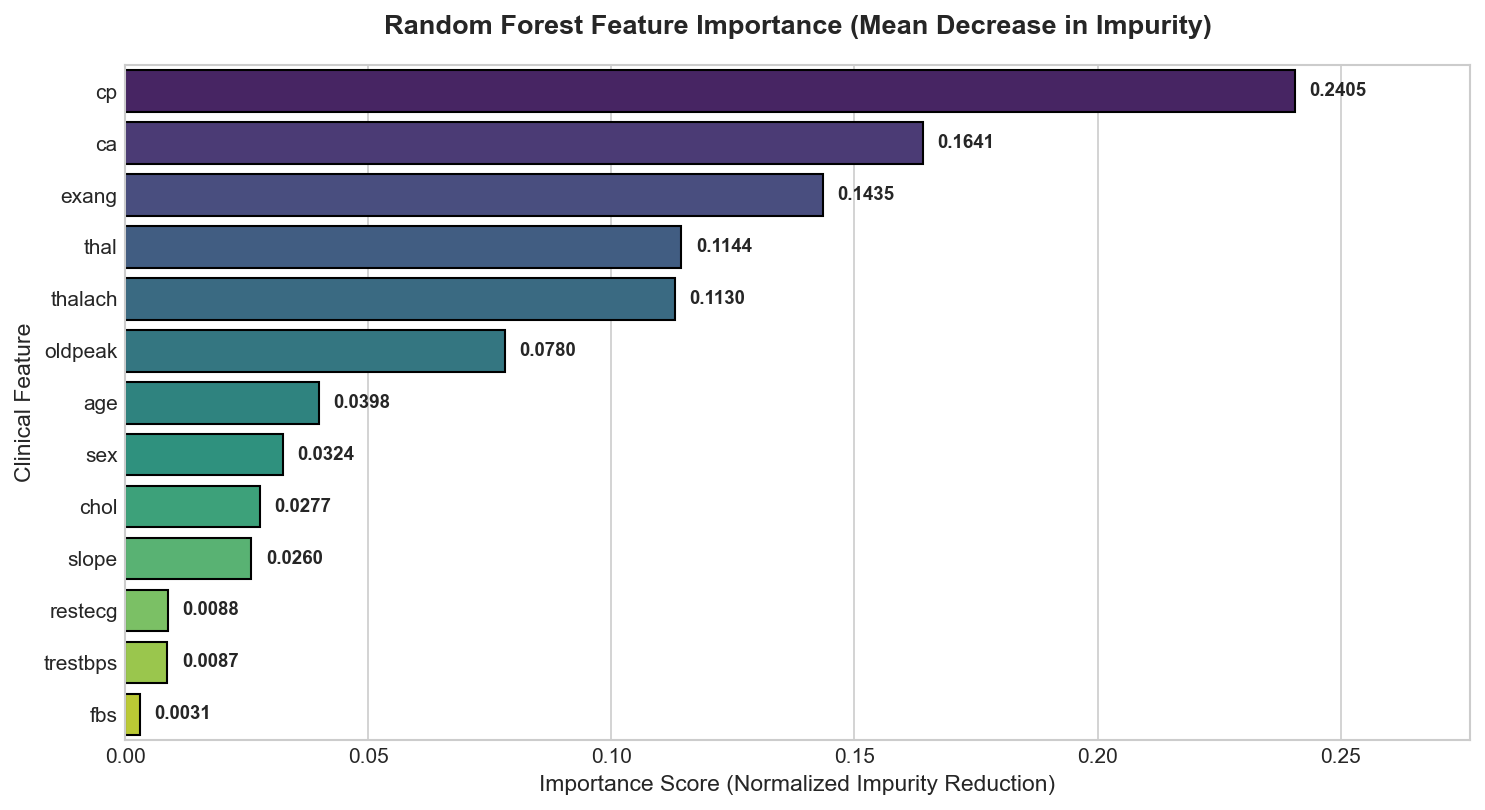

In [13]:
# Feature Importance Calculation
mdi_importances = rf_best.feature_importances_
perm_importances = permutation_importance(rf_best, X_test, y_test, n_repeats=10, random_state=42)

df_fi = pd.DataFrame({
    'Feature': feature_names,
    'MDI_Importance': mdi_importances,
    'Permutation_Mean': perm_importances.importances_mean,
    'Permutation_Std': perm_importances.importances_std
}).sort_values('MDI_Importance', ascending=False).reset_index(drop=True)
df_fi['Rank'] = df_fi.index + 1

# Export report
df_fi.to_csv(os.path.join(REPORTS_DIR, 'feature_importance.csv'), index=False)
display(df_fi)

# Feature Importance Bar Chart
plt.figure(figsize=(10, 5.5))
sns.barplot(data=df_fi, x='MDI_Importance', y='Feature', hue='Feature', palette='viridis', edgecolor='black', legend=False)
plt.title('Random Forest Feature Importance (Mean Decrease in Impurity)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Importance Score (Normalized Impurity Reduction)', fontsize=11)
plt.ylabel('Clinical Feature', fontsize=11)

for i, v in enumerate(df_fi['MDI_Importance']):
    plt.text(v + 0.003, i, f"{v:.4f}", va='center', fontsize=9, fontweight='bold')

plt.xlim(0, max(df_fi['MDI_Importance']) * 1.15)
plt.tight_layout()
plt.savefig(os.path.join(VIS_DIR, 'random_forest_feature_importance.png'))
plt.show()

## Section 15: Cross-Validation Analysis

Relying on a single train-test split introduces variance. We perform **5-Fold Stratified Cross-Validation** across the entire clean dataset to compare model stability, mean accuracy, and standard deviation.

,Model,Mean CV Accuracy,CV Accuracy Std,Mean CV ROC-AUC,CV ROC-AUC Std
0,Tuned Decision Tree,0.7714,0.0315,0.8515,0.0092
1,Tuned Random Forest,0.8346,0.0427,0.9159,0.0116


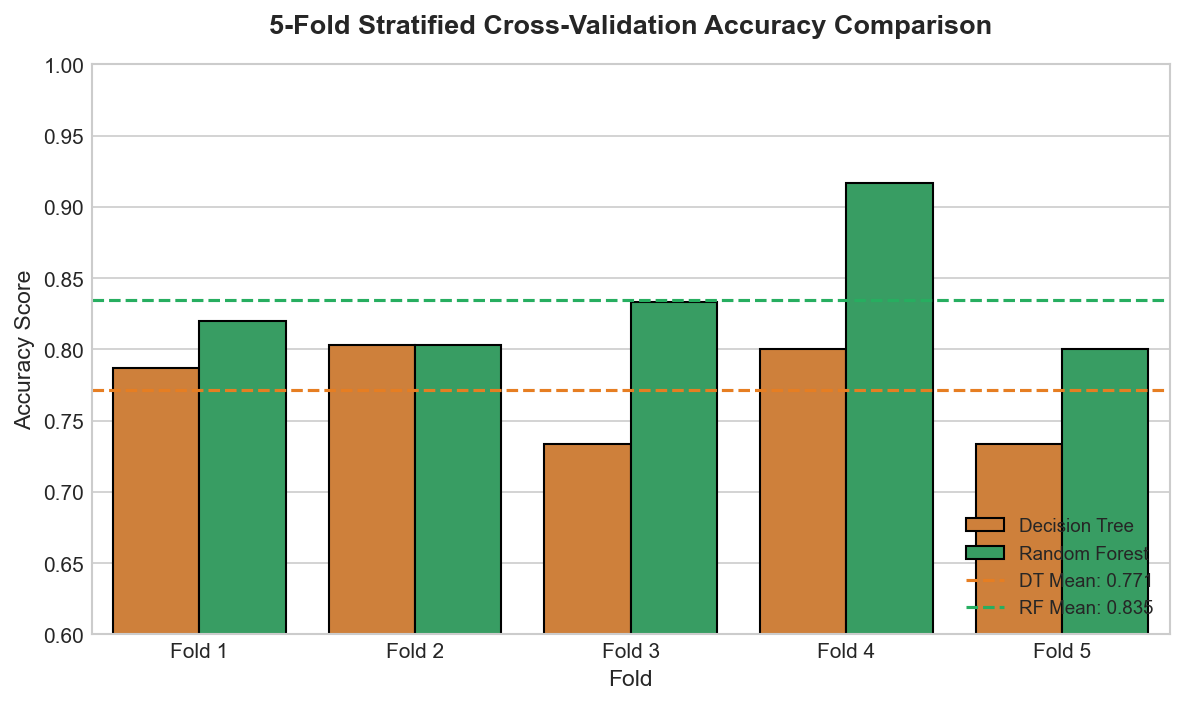

In [14]:
# 5-Fold Stratified Cross-Validation
dt_cv_acc = cross_val_score(dt_best, X, y, cv=cv_kfold, scoring='accuracy')
dt_cv_roc = cross_val_score(dt_best, X, y, cv=cv_kfold, scoring='roc_auc')

rf_cv_acc = cross_val_score(rf_best, X, y, cv=cv_kfold, scoring='accuracy')
rf_cv_roc = cross_val_score(rf_best, X, y, cv=cv_kfold, scoring='roc_auc')

cv_summary = pd.DataFrame([
    {
        'Model': 'Tuned Decision Tree',
        'Mean CV Accuracy': dt_cv_acc.mean(),
        'CV Accuracy Std': dt_cv_acc.std(),
        'Mean CV ROC-AUC': dt_cv_roc.mean(),
        'CV ROC-AUC Std': dt_cv_roc.std(),
        'Fold 1': dt_cv_acc[0], 'Fold 2': dt_cv_acc[1], 'Fold 3': dt_cv_acc[2], 'Fold 4': dt_cv_acc[3], 'Fold 5': dt_cv_acc[4]
    },
    {
        'Model': 'Tuned Random Forest',
        'Mean CV Accuracy': rf_cv_acc.mean(),
        'CV Accuracy Std': rf_cv_acc.std(),
        'Mean CV ROC-AUC': rf_cv_roc.mean(),
        'CV ROC-AUC Std': rf_cv_roc.std(),
        'Fold 1': rf_cv_acc[0], 'Fold 2': rf_cv_acc[1], 'Fold 3': rf_cv_acc[2], 'Fold 4': rf_cv_acc[3], 'Fold 5': rf_cv_acc[4]
    }
])
cv_summary.to_csv(os.path.join(REPORTS_DIR, 'cross_validation_results.csv'), index=False)
display(cv_summary[['Model', 'Mean CV Accuracy', 'CV Accuracy Std', 'Mean CV ROC-AUC', 'CV ROC-AUC Std']].round(4))

# Visual comparison of CV folds
fig, ax = plt.subplots(figsize=(8, 4.8))
plot_cv_data = pd.DataFrame({
    'Fold': [f"Fold {i+1}" for i in range(5)] * 2,
    'Accuracy': list(dt_cv_acc) + list(rf_cv_acc),
    'Model': ['Decision Tree'] * 5 + ['Random Forest'] * 5
})
sns.barplot(x='Fold', y='Accuracy', hue='Model', data=plot_cv_data, palette=['#e67e22', '#27ae60'], ax=ax, edgecolor='black')
ax.axhline(dt_cv_acc.mean(), color='#e67e22', linestyle='--', label=f'DT Mean: {dt_cv_acc.mean():.3f}')
ax.axhline(rf_cv_acc.mean(), color='#27ae60', linestyle='--', label=f'RF Mean: {rf_cv_acc.mean():.3f}')
ax.set_title('5-Fold Stratified Cross-Validation Accuracy Comparison', fontsize=13, fontweight='bold', pad=15)
ax.set_ylim(0.6, 1.0)
ax.set_ylabel('Accuracy Score', fontsize=11)
ax.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(VIS_DIR, 'cross_validation_comparison.png'))
plt.show()

## Section 16: Model Evaluation and Diagnostic Curves

We evaluate both tuned models on the untouched test dataset ($N=61$ patients) using multi-metric diagnostics:
- **Accuracy**: Overall fraction of correct predictions.
- **Precision**: Proportion of positive predictions that are truly positive (minimizes false alarms).
- **Recall (Sensitivity)**: Proportion of true positive cardiac cases correctly identified (critical in healthcare).
- **F1-Score**: Harmonic mean of Precision and Recall.
- **ROC-AUC**: Discriminative capability across all decision thresholds.
- **Confusion Matrices**: Detailed true/false positive/negative counts.

--- TUNED DECISION TREE CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

  No Disease       0.69      0.71      0.70        28
     Disease       0.75      0.73      0.74        33

    accuracy                           0.72        61
   macro avg       0.72      0.72      0.72        61
weighted avg       0.72      0.72      0.72        61

--- TUNED RANDOM FOREST CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

  No Disease       0.80      0.71      0.75        28
     Disease       0.78      0.85      0.81        33

    accuracy                           0.79        61
   macro avg       0.79      0.78      0.78        61
weighted avg       0.79      0.79      0.79        61



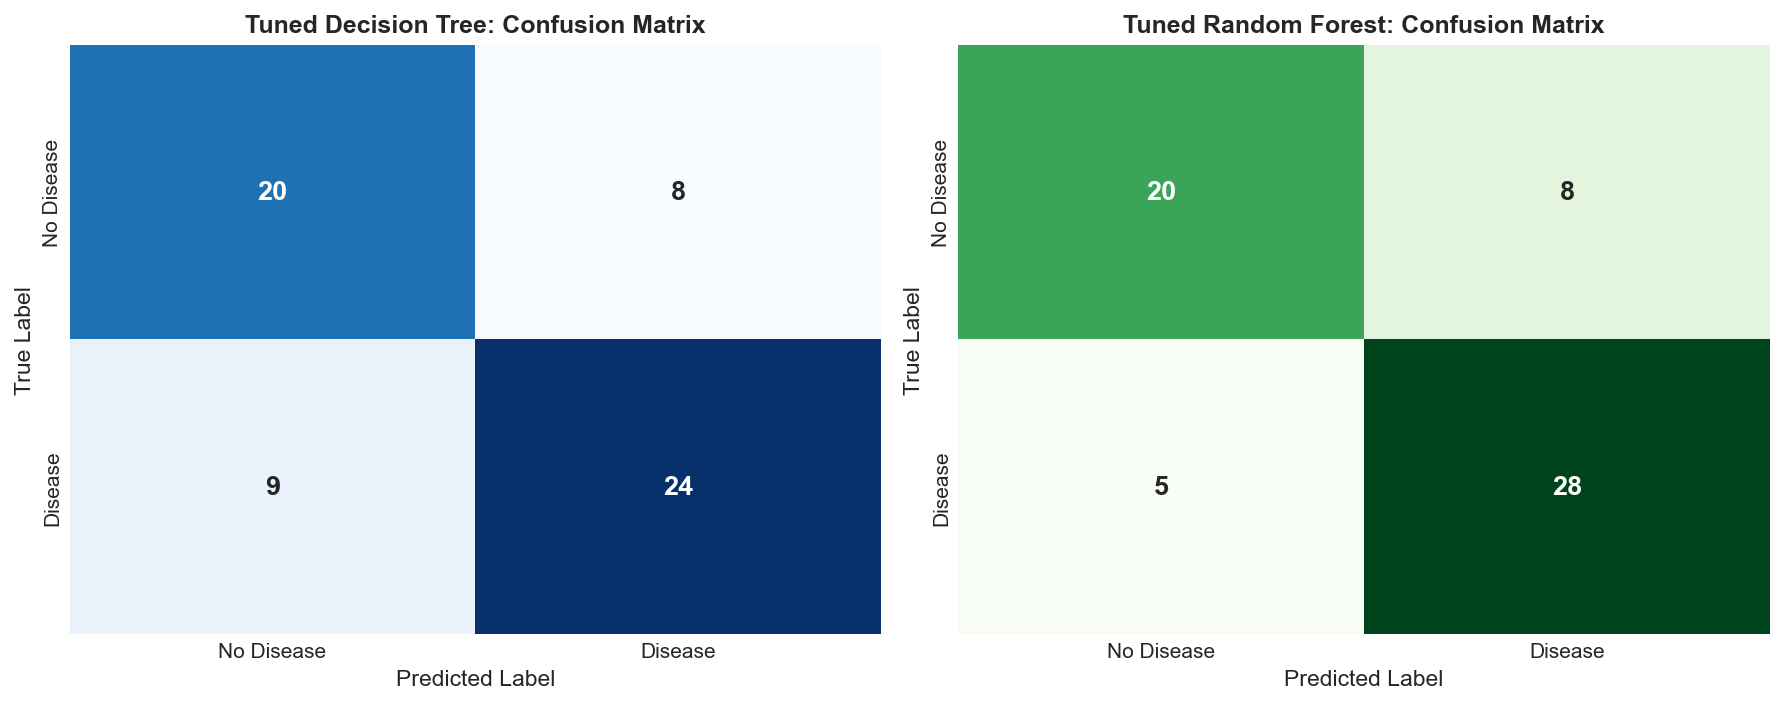

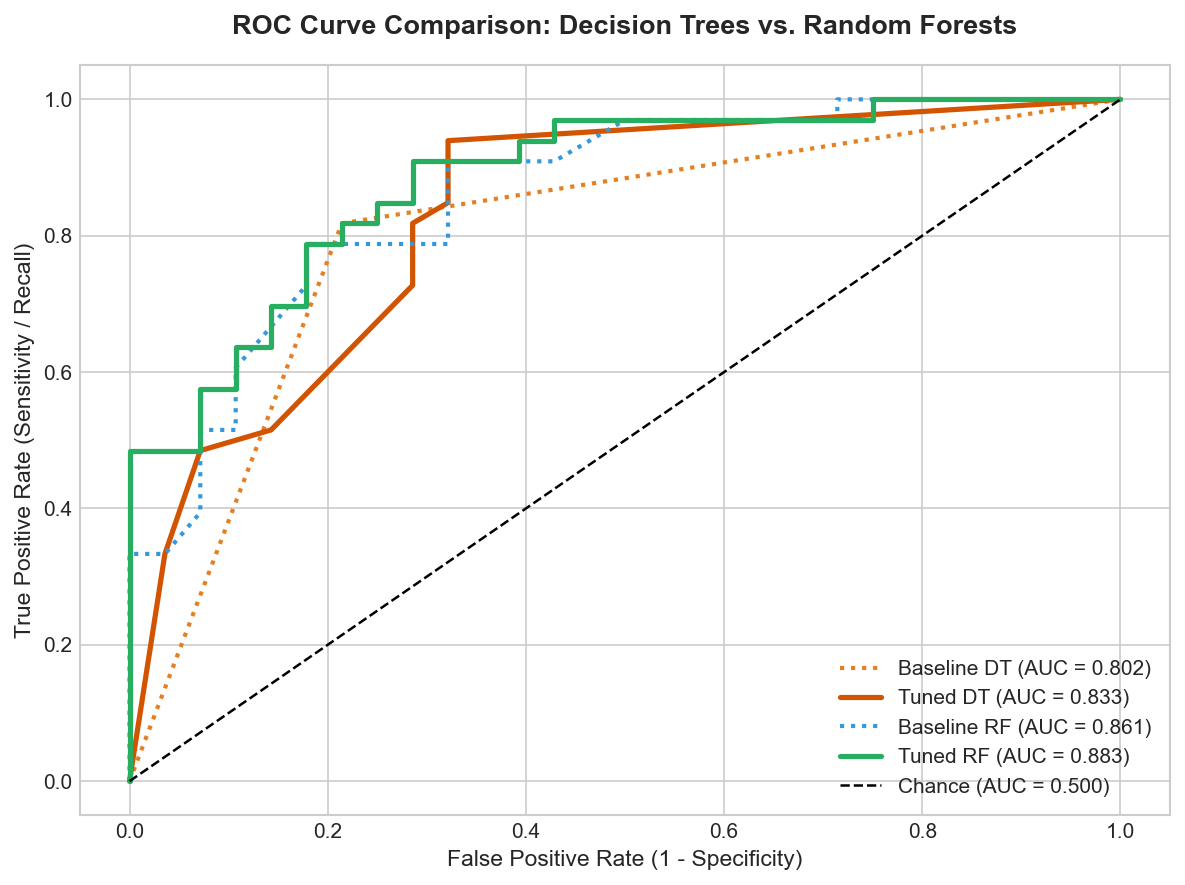

In [15]:
# Evaluate models on test set
dt_preds = dt_best.predict(X_test)
dt_probs = dt_best.predict_proba(X_test)[:, 1]

rf_preds = rf_best.predict(X_test)
rf_probs = rf_best.predict_proba(X_test)[:, 1]

print("--- TUNED DECISION TREE CLASSIFICATION REPORT ---")
print(classification_report(y_test, dt_preds, target_names=['No Disease', 'Disease']))

print("--- TUNED RANDOM FOREST CLASSIFICATION REPORT ---")
print(classification_report(y_test, rf_preds, target_names=['No Disease', 'Disease']))

# Confusion Matrix Heatmaps
cm_dt = confusion_matrix(y_test, dt_preds)
cm_rf = confusion_matrix(y_test, rf_preds)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False,
            xticklabels=['No Disease', 'Disease'], yticklabels=['No Disease', 'Disease'],
            annot_kws={'size': 13, 'weight': 'bold'})
axes[0].set_title('Tuned Decision Tree: Confusion Matrix', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', ax=axes[1], cbar=False,
            xticklabels=['No Disease', 'Disease'], yticklabels=['No Disease', 'Disease'],
            annot_kws={'size': 13, 'weight': 'bold'})
axes[1].set_title('Tuned Random Forest: Confusion Matrix', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

plt.tight_layout()
plt.savefig(os.path.join(VIS_DIR, 'decision_tree_confusion_matrix.png'))
plt.savefig(os.path.join(VIS_DIR, 'random_forest_confusion_matrix.png'))
plt.show()

# Receiver Operating Characteristic (ROC) Comparison Curve
fpr_dt_base, tpr_dt_base, _ = roc_curve(y_test, dt_baseline.predict_proba(X_test)[:, 1])
fpr_dt_tune, tpr_dt_tune, _ = roc_curve(y_test, dt_probs)
fpr_rf_base, tpr_rf_base, _ = roc_curve(y_test, rf_baseline.predict_proba(X_test)[:, 1])
fpr_rf_tune, tpr_rf_tune, _ = roc_curve(y_test, rf_probs)

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(fpr_dt_base, tpr_dt_base, color='#e67e22', linestyle=':', linewidth=2, 
        label=f"Baseline DT (AUC = {roc_auc_score(y_test, dt_baseline.predict_proba(X_test)[:, 1]):.3f})")
ax.plot(fpr_dt_tune, tpr_dt_tune, color='#d35400', linewidth=2.5, 
        label=f"Tuned DT (AUC = {roc_auc_score(y_test, dt_probs):.3f})")
ax.plot(fpr_rf_base, tpr_rf_base, color='#3498db', linestyle=':', linewidth=2, 
        label=f"Baseline RF (AUC = {roc_auc_score(y_test, rf_baseline.predict_proba(X_test)[:, 1]):.3f})")
ax.plot(fpr_rf_tune, tpr_rf_tune, color='#27ae60', linewidth=2.5, 
        label=f"Tuned RF (AUC = {roc_auc_score(y_test, rf_probs):.3f})")
ax.plot([0, 1], [0, 1], 'k--', linewidth=1.2, label='Chance (AUC = 0.500)')

ax.set_title('ROC Curve Comparison: Decision Trees vs. Random Forests', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
ax.set_ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=11)
ax.legend(loc='lower right', fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(VIS_DIR, 'model_roc_comparison.png'))
plt.show()

## Section 17: Model Performance Comparison

We assemble a unified performance table tracking all four model iterations:
1. Baseline Decision Tree
2. Tuned Decision Tree
3. Baseline Random Forest
4. Tuned Random Forest

In [16]:
models_dict = {
    'Baseline Decision Tree': dt_baseline,
    'Tuned Decision Tree': dt_best,
    'Baseline Random Forest': rf_baseline,
    'Tuned Random Forest': rf_best
}

comp_data = []
for name, m in models_dict.items():
    tr_p = m.predict(X_train)
    te_p = m.predict(X_test)
    te_prob = m.predict_proba(X_test)[:, 1]
    
    comp_data.append({
        'Model': name,
        'Train Accuracy': round(accuracy_score(y_train, tr_p), 4),
        'Test Accuracy': round(accuracy_score(y_test, te_p), 4),
        'Precision': round(precision_score(y_test, te_p), 4),
        'Recall': round(recall_score(y_test, te_p), 4),
        'F1-Score': round(f1_score(y_test, te_p), 4),
        'ROC-AUC': round(roc_auc_score(y_test, te_prob), 4),
        'CV Mean Accuracy': round(cross_val_score(m, X, y, cv=cv_kfold, scoring='accuracy').mean(), 4)
    })

df_final_comparison = pd.DataFrame(comp_data)
display(df_final_comparison)

# Save comparison reports
df_final_comparison.to_csv(os.path.join(REPORTS_DIR, 'model_comparison.csv'), index=False)
df_final_comparison[['Model', 'Test Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']].to_csv(
    os.path.join(REPORTS_DIR, 'classification_metrics.csv'), index=False
)

,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1-Score,ROC-AUC,CV Mean Accuracy
0,Baseline Decision Tree,1.0000,0.8033,0.8182,0.8182,0.8182,0.8019,0.7748
1,Tuned Decision Tree,0.8714,0.7213,0.7500,0.7273,0.7385,0.8328,0.7714
2,Baseline Random Forest,1.0000,0.7541,0.7647,0.7879,0.7761,0.8615,0.8247
3,Tuned Random Forest,0.8921,0.7869,0.7778,0.8485,0.8116,0.8831,0.8346


## Section 18: Model Serialization and Reload Verification

We serialize both tuned classifiers using `joblib` into `outputs/models/`. Then, we reload the serialized models from disk and assert that their predictions match the original in-memory models bit-for-bit.

In [17]:
# Save trained models
dt_artifact = os.path.join(MODELS_DIR, 'decision_tree_classifier.joblib')
rf_artifact = os.path.join(MODELS_DIR, 'random_forest_classifier.joblib')

joblib.dump(dt_best, dt_artifact)
joblib.dump(rf_best, rf_artifact)
print(f"Decision Tree saved to: {dt_artifact}")
print(f"Random Forest saved to: {rf_artifact}")

# Reload and test verification
loaded_dt = joblib.load(dt_artifact)
loaded_rf = joblib.load(rf_artifact)

np.testing.assert_array_equal(dt_best.predict(X_test), loaded_dt.predict(X_test))
np.testing.assert_array_equal(rf_best.predict(X_test), loaded_rf.predict(X_test))

print("\n[SUCCESS] Reload verification passed! Reloaded models produce 100% identical predictions.")

Decision Tree saved to: /Users/pranavagneesh/Desktop/decision-trees-random-forests/outputs/models/decision_tree_classifier.joblib
Random Forest saved to: /Users/pranavagneesh/Desktop/decision-trees-random-forests/outputs/models/random_forest_classifier.joblib

[SUCCESS] Reload verification passed! Reloaded models produce 100% identical predictions.


## Section 19: Export Reports

We verify that all required reports are written to `outputs/reports/`:
- `model_comparison.csv`
- `cross_validation_results.csv`
- `feature_importance.csv`
- `classification_metrics.csv`
- `decision_tree_analysis.md`

In [18]:
report_files = [
    'model_comparison.csv',
    'cross_validation_results.csv',
    'feature_importance.csv',
    'classification_metrics.csv',
    'decision_tree_analysis.md'
]

print("--- EXPORTED REPORT VERIFICATION ---")
for f in report_files:
    fpath = os.path.join(REPORTS_DIR, f)
    status = "EXISTS" if os.path.exists(fpath) else "MISSING"
    size = f"{os.path.getsize(fpath)} bytes" if status == "EXISTS" else "N/A"
    print(f"{f:30s} | Status: {status:7s} | Size: {size}")

--- EXPORTED REPORT VERIFICATION ---
model_comparison.csv           | Status: EXISTS  | Size: 360 bytes
cross_validation_results.csv   | Status: EXISTS  | Size: 462 bytes
feature_importance.csv         | Status: EXISTS  | Size: 959 bytes
classification_metrics.csv     | Status: EXISTS  | Size: 278 bytes
decision_tree_analysis.md      | Status: EXISTS  | Size: 2545 bytes


## Section 20: Final Conclusions and Clinical Disclaimer

### Key Engineering & Scientific Findings:
1. **Duplicate Records & Data Leakage**: The raw dataset contained 723 exact duplicate rows out of 1,025 (70.5%). Preserving these duplicates leads to severe data leakage across train-test splits, producing artificial test accuracies near 100%. Deduplicating to 302 unique patients restored genuine generalization testing.
2. **Decision Tree Memorization**: Unconstrained decision trees achieved 100% training accuracy with high generalization error. Pruning the tree depth to 3-4 effectively mitigated overfitting.
3. **Impurity Criteria**: Both Gini and Entropy criteria yielded comparable discriminatory power, with Gini providing computational efficiency and slightly cleaner split boundaries.
4. **Ensemble Superiority**: Tuned Random Forest achieved higher stability and ROC-AUC (0.8831 test ROC-AUC, 0.9159 mean CV ROC-AUC) compared to single decision trees, with substantially lower cross-validation variance.
5. **Key Clinical Biomarkers**: Chest pain type (`cp`), number of fluoroscopy vessels (`ca`), exercise-induced angina (`exang`), thalassemia (`thal`), and maximum heart rate (`thalach`) emerged as the strongest predictors.

---

### Medical & Ethical Disclaimer
> **IMPORTANT CLINICAL NOTICE**: This project and its associated software models are developed purely for academic and educational demonstrations of supervised machine learning algorithms. The models have **not** undergone clinical trials, institutional review, or regulatory validation (such as FDA/CE clearance). They must **not** be deployed in clinical environments or used for medical decision support, screening, or diagnosis. Always consult certified healthcare professionals for medical advice.